# Ripasso di Machine Learning: una mappa dei modelli

Foglio di appunti **condiviso**: lo leggiamo e lo completiamo insieme. Le celle intitolate **"Le tue parole"** sono per te: scrivi lì con parole tue, io correggo con garbo.

**Come è fatto.** Ogni modello ha una scheda con le stesse cinque voci:
1. **Idea** in una frase
2. **Peculiarità**: cosa lo distingue dagli altri
3. **Forte** e 4. **Debole**
5. **Manopole**: gli iperparametri che finiscono nella griglia del progetto

Tutti i classificatori sono provati **sugli stessi tre dataset giocattolo**, così vedi la differenza e non solo la descrizione.

**Fonti.** Le etichette `[corso]` indicano cose dette nei notebook del prof (01-09) o nelle slide. Le etichette `[mio]` sono aggiunte mie di conoscenza generale: confrontale con le slide prima di fidarti.

**Prerequisito.** Scala sempre le feature (`StandardScaler`) per i modelli che usano distanze o gradient descent: lo facciamo dentro una `Pipeline`.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.datasets import make_blobs, make_moons, make_circles, load_digits
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Perceptron, LogisticRegression, LinearRegression, Ridge, RidgeCV
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.decomposition import PCA, KernelPCA
from sklearn.dummy import DummyClassifier
from sklearn.metrics import mean_squared_error

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})
CMAP = plt.cm.coolwarm

## 0. I tre dataset giocattolo

Servono per vedere **che forma di confine** sa disegnare ciascun modello.

- **separabile**: due nuvole divisibili da una retta
- **lune**: due mezzelune intrecciate, serve un confine curvo
- **cerchi**: una classe dentro l'altra, nessuna retta può funzionare

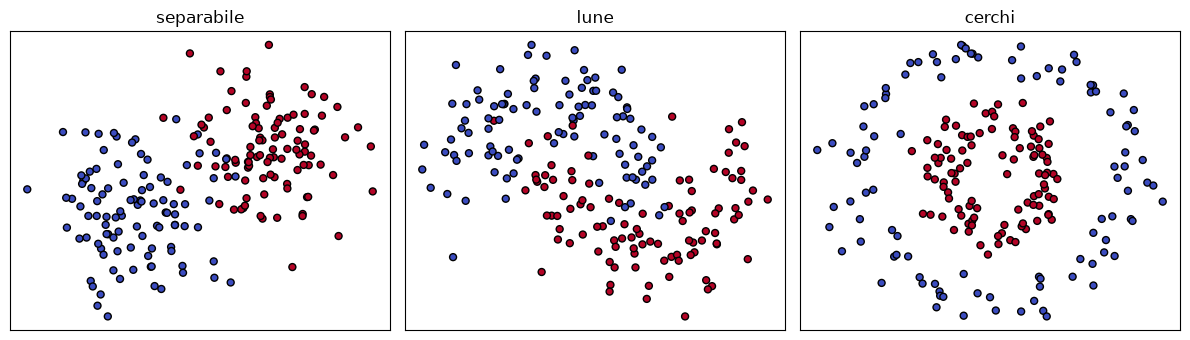

In [3]:
def crea_dati():
    X1, y1 = make_blobs(n_samples=200, centers=[[-2, -1], [2, 1]], cluster_std=1.2, random_state=0)
    X2, y2 = make_moons(200, noise=0.25, random_state=0)
    X3, y3 = make_circles(200, noise=0.1, factor=0.4, random_state=0)
    dati = {"separabile": (X1, y1), "lune": (X2, y2), "cerchi": (X3, y3)}
    split = {k: train_test_split(X, y, test_size=0.3, stratify=y, random_state=0) for k, (X, y) in dati.items()}
    return dati, split

DATI, SPLIT = crea_dati()

def disegna(ax, modello, nome, titolo=""):
    Xtr, Xte, ytr, yte = SPLIT[nome]
    mod = clone(modello).fit(Xtr, ytr)
    X = DATI[nome][0]
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .7, X[:, 0].max() + .7, 250),
                         np.linspace(X[:, 1].min() - .7, X[:, 1].max() + .7, 250))
    Z = mod.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap=CMAP, levels=[-.5, .5, 1.5])
    ax.scatter(*Xtr.T, c=ytr, cmap=CMAP, edgecolor="k", s=25, label="train")
    ax.scatter(*Xte.T, c=yte, cmap=CMAP, edgecolor="k", s=70, marker="s", label="test")
    acc = mod.score(Xte, yte)
    ax.set_title(f"{titolo} {nome}: acc test = {acc:.2f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    return mod, acc

def scheda_grafica(modello, titolo=""):
    fig, axs = plt.subplots(1, 3, figsize=(14, 4))
    for ax, nome in zip(axs, DATI):
        disegna(ax, modello, nome, titolo)
    axs[0].legend(loc="lower left", fontsize=8)
    plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (nome, (X, y)) in zip(axs, DATI.items()):
    ax.scatter(*X.T, c=y, cmap=CMAP, edgecolor="k", s=25); ax.set_title(nome); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

# Parte A. Classificazione

Il filo conduttore, in una riga: **tutti questi modelli calcolano un punteggio e poi decidono la classe**. Cambia *come* scelgono i pesi e *che forma* può avere il confine.

Prima di tutto la baseline(il dummy), che non è un modello da vincere ma un **metro**.

## A0. Dummy classifier `[corso]`

- **Idea**: ignora completamente le feature e predice sempre la classe più frequente.
- **Peculiarità**: non impara niente. Serve da riferimento minimo: se il tuo modello non lo batte, non ha imparato nulla.
- **Forte**: costa zero, ti dice quanto vale "tirare a indovinare" con quelle proporzioni di classi.
- **Debole**: non è un candidato, è solo il metro. Con classi sbilanciate può avere accuracy alta (es. 95%) senza servire a niente.

In [4]:
for nome, (X, y) in DATI.items():
    Xtr, Xte, ytr, yte = SPLIT[nome]
    d = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
    print(f"{nome:11s} dummy acc test = {d.score(Xte, yte):.2f}   (classi bilanciate: ci aspettiamo circa 0.5)")

separabile  dummy acc test = 0.50   (classi bilanciate: ci aspettiamo circa 0.5)
lune        dummy acc test = 0.50   (classi bilanciate: ci aspettiamo circa 0.5)
cerchi      dummy acc test = 0.50   (classi bilanciate: ci aspettiamo circa 0.5)


## A1. Perceptron `[corso]`

- **Idea**: calcola $z = \mathbf{w}^\top \mathbf{x}$ e usa una **soglia**: classe +1 se $z\ge 0$, altrimenti −1. Ad ogni errore sposta i pesi verso il punto sbagliato.
- **Peculiarità**: l'errore è **0 o 1** (giusto/sbagliato), non dice "di quanto" sbagli. Nessuna probabilità.
- **Forte**: semplicissimo e veloce. Se i dati sono linearmente separabili, **converge** a una retta che li separa tutti `[corso]`.
- **Debole**: se i dati **non** sono separabili non si stabilizza mai: i pesi continuano a oscillare `[corso]`. Tra le infinite rette corrette ne prende una qualunque, non la migliore `[mio]`.
- **Manopole**: `eta0` (learning rate), `max_iter`.

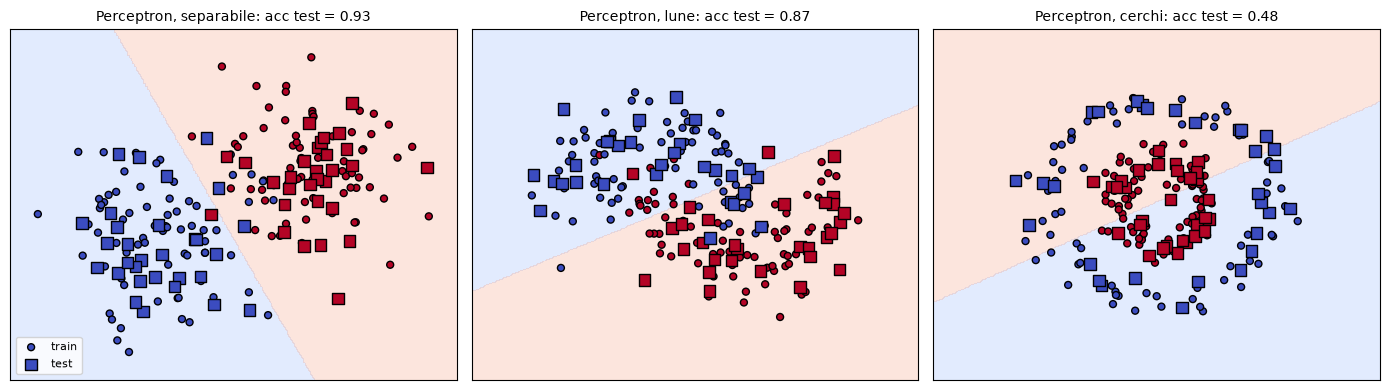

In [5]:
scheda_grafica(make_pipeline(StandardScaler(), Perceptron(random_state=0)), "Perceptron,")

**Cosa guardare nel grafico.** Sul primo dataset ci riesce. Su lune e cerchi il confine è comunque **una retta**: è l'unica forma che può disegnare, quindi non può cavarsela.

## A2. Adaline `[corso]`

- **Idea**: stesso $z=\mathbf{w}^\top\mathbf{x}$ del Perceptron, ma l'errore si calcola su $z$ **stesso** (attivazione lineare), non sulla soglia. Si minimizza la somma dei quadrati degli errori.
- **Peculiarità**: l'errore è continuo, quindi esiste una funzione da minimizzare (convessa) e si può usare **gradient descent** oppure la **closed form** (pseudo-inversa).
- **Forte**: converge sempre a un minimo (con $\eta$ adatto), anche con dati non separabili. Ottimo per capire il gradient descent.
- **Debole**: l'errore quadratico su etichette ±1 punisce anche i punti "troppo giusti" (molto lontani dal confine) `[mio]`. Confine comunque lineare. Sensibile alla scala delle feature.
- **Manopole**: $\eta$ e numero di epoche (per GD).

Per questo ripasso lo implemento in closed form, che per questo scopo dà lo stesso minimo del GD ben convergente `[corso]`: regressione lineare su etichette −1/+1, poi si prende il segno.

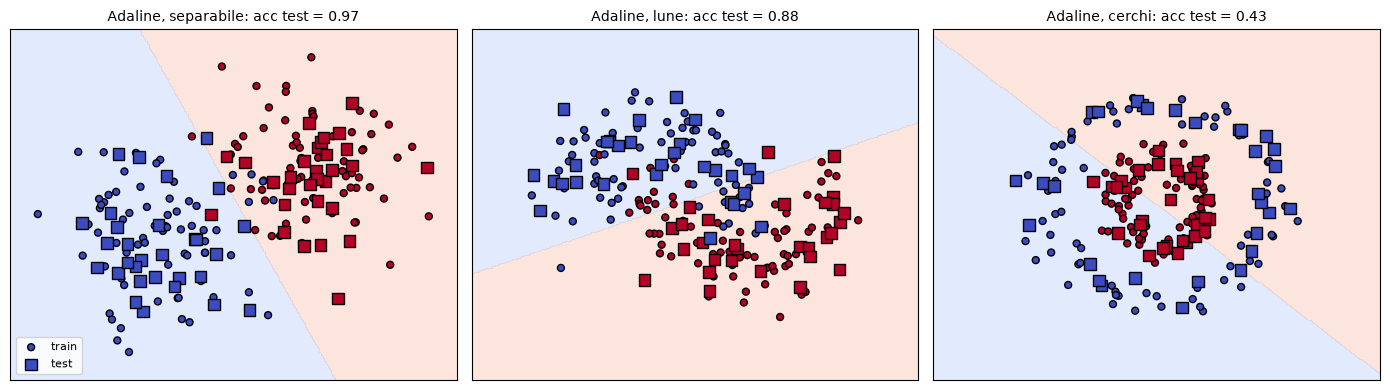

In [6]:
class AdalineCF(BaseEstimator, ClassifierMixin):
    # Adaline in closed form (minimi quadrati su y in {-1,+1}), poi soglia sul segno
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        t = np.where(y == self.classes_[1], 1.0, -1.0)
        self.lin_ = LinearRegression().fit(X, t)
        return self
    def predict(self, X):
        return np.where(self.lin_.predict(X) >= 0, self.classes_[1], self.classes_[0])

scheda_grafica(make_pipeline(StandardScaler(), AdalineCF()), "Adaline,")

## A3. Regressione logistica `[corso]`

- **Idea**: $z=\mathbf{w}^\top\mathbf{x}$, poi la **sigmoide** $\sigma(z)=1/(1+e^{-z})$ trasforma $z$ in una **probabilità** di classe positiva. Si decide con soglia 0.5 (modificabile).
- **Peculiarità**: restituisce **probabilità**, quindi puoi spostare la soglia per scegliere tra precision e recall. Si allena minimizzando la log-loss.
- **Forte**: modello di riferimento per cominciare. Probabilità, confine interpretabile (i pesi dicono quali feature contano), veloce. Regolarizzata di default.
- **Debole**: confine **lineare** nello spazio delle feature (si può curvare con `PolynomialFeatures`, come nel notebook 06).
- **Manopole**: `C` = **inverso** della regolarizzazione (C piccolo = più regolarizzato, `C=np.inf` = nessuna), penalità L1/L2.

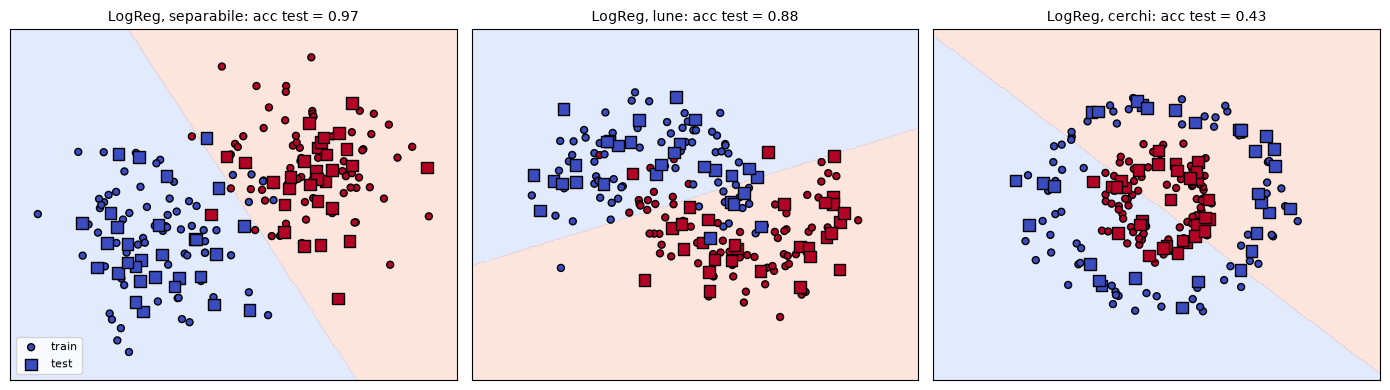

In [7]:
scheda_grafica(make_pipeline(StandardScaler(), LogisticRegression(C=1.0)), "LogReg,")

**Prova tu.** Cambia `C` in `0.001` e in `1000` e guarda come cambia l'inclinazione della retta (non la forma: resta una retta).

**Perceptron, Adaline e logistica in una frase**: stesso $z=\mathbf{w}^\top\mathbf{x}$, tre modi diversi di *misurare l'errore*: errore di soglia (0/1), errore quadratico su $z$, log-loss su $\sigma(z)$.

## A4. SVM lineare `[corso]`

- **Idea**: tra tutte le rette che separano i dati, scegli quella con il **margine massimo** (la striscia più larga senza punti in mezzo, larga $2/\|\mathbf{w}\|$). * Margin = space between the line to the first vector, larger it is better the algorithm is working
- **Peculiarità**: il confine dipende **solo dai support vector**, cioè i pochi punti che toccano il margine. Gli altri si possono cancellare senza cambiare nulla.
- **Forte**: scelta "ben definita" tra le infinite rette (a differenza del Perceptron). Ottima generalizzazione con dati in alta dimensione.
- **Debole**: nessuna probabilità diretta. `SVC` va lento con decine di migliaia di righe `[corso]`/sklearn. Lineare.
- **Manopole**: `C` (margine morbido: C grande = poca tolleranza agli errori, margine stretto; C piccolo = margine largo).
Whats a vector, a vector V is about the feature of our Matrix in input.
Why stands for Support vectors? Because we consider the margin line the one that is not fully dotted like a bridge and we consider the vectors inside the margin and on the margin line like the columns that supports this margin, if we move our support vectors outside the margin it falls and it moves also.
This algorithm take in input also an Hyperparameter C and it can change a lot about the margin (smaller or larger)

## Quanti support vector? Pochi o tanti

Un **support vector** è un punto di training che sta sul bordo del margine, dentro il margine o dalla parte sbagliata. Il confine dipende **solo da questi punti**: se togli un punto lontano, il confine non cambia.

Il numero di support vector **non è un obiettivo**, è un sintomo. Va letto insieme a accuracy di train e di test:

| Situazione | Support vector | Cosa significa |
|---|---|---|
| Dati separabili, `C` alto | pochi | problema pulito, modello semplice, predizione veloce |
| `C` piccolo | molti | margine largo, più regolarizzato (più bias, meno varianza) |
| Classi sovrapposte | molti | dati difficili, nessun margine pulito |
| RBF con `gamma` altissimo | quasi tutti | overfitting: train alto, test basso |

Per scegliere `C` e `gamma` **non** si contano i support vector: si usa la validation curve o la GridSearchCV.

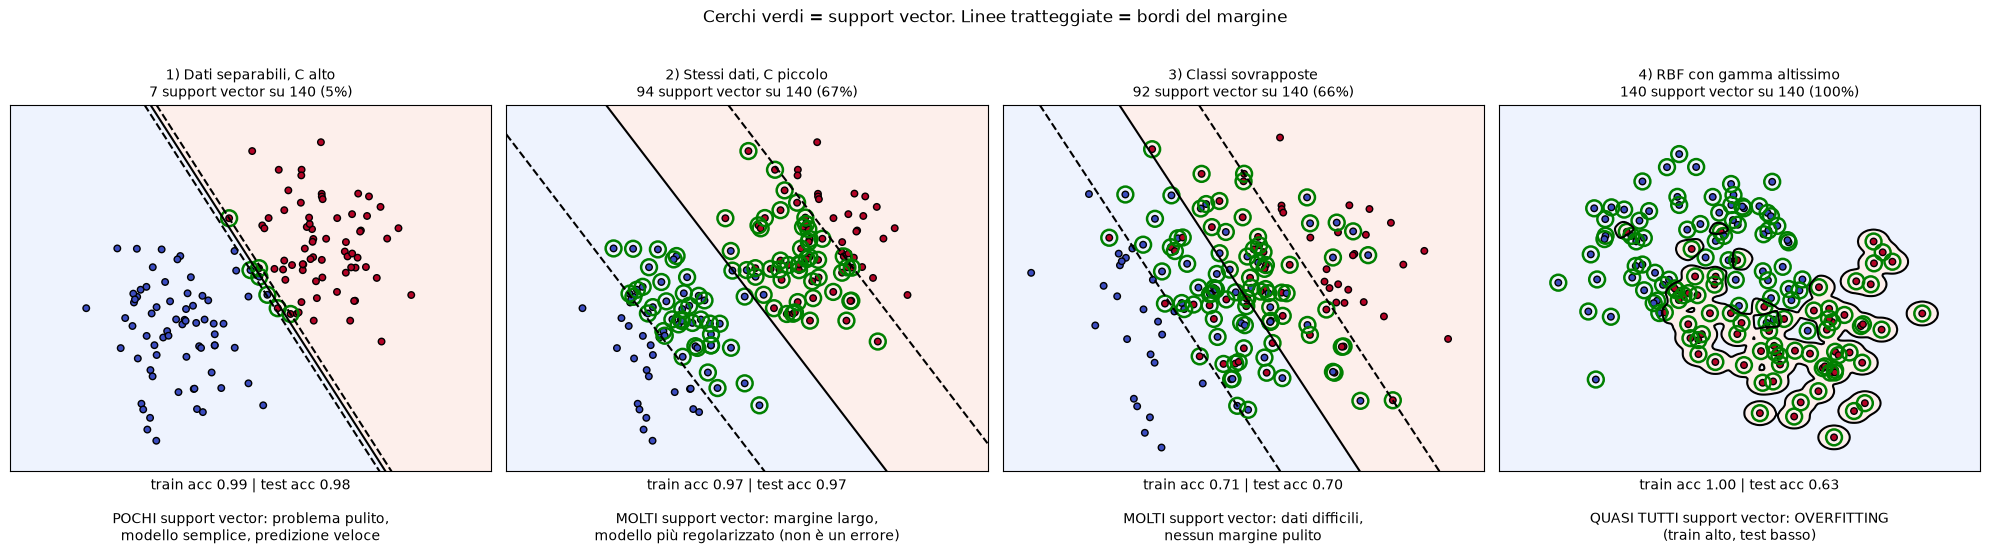

In [19]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

casi = [
    ("1) Dati separabili, C alto", make_blobs(200, centers=[[-2,-1],[2,1]], cluster_std=1.0, random_state=0),
     SVC(kernel="linear", C=100), "POCHI support vector: problema pulito,\nmodello semplice, predizione veloce"),
    ("2) Stessi dati, C piccolo", make_blobs(200, centers=[[-2,-1],[2,1]], cluster_std=1.0, random_state=0),
     SVC(kernel="linear", C=0.01), "MOLTI support vector: margine largo,\nmodello più regolarizzato (non è un errore)"),
    ("3) Classi sovrapposte", make_blobs(200, centers=[[-1,-0.5],[1,0.5]], cluster_std=1.6, random_state=0),
     SVC(kernel="linear", C=1), "MOLTI support vector: dati difficili,\nnessun margine pulito"),
    ("4) RBF con gamma altissimo", make_moons(200, noise=0.3, random_state=0),
     SVC(kernel="rbf", C=1, gamma=100), "QUASI TUTTI support vector: OVERFITTING\n(train alto, test basso)"),
]

fig, axs = plt.subplots(1, 4, figsize=(20, 5.4))
for ax, (titolo, (X, y), svm, nota) in zip(axs, casi):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
    sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    svm.fit(Xtr_s, ytr)
    xx, yy = np.meshgrid(np.linspace(-3, 3, 250), np.linspace(-3, 3, 250))
    D = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, D > 0, alpha=.15, cmap="coolwarm")
    ax.contour(xx, yy, D, levels=[0], colors="k")
    if svm.kernel == "linear":
        ax.contour(xx, yy, D, levels=[-1, 1], colors="k", linestyles="--")
    ax.scatter(*Xtr_s.T, c=ytr, cmap="coolwarm", edgecolor="k", s=22)
    ax.scatter(*svm.support_vectors_.T, s=130, facecolors="none", edgecolors="g", linewidths=1.8)
    n_sv, n = len(svm.support_vectors_), len(Xtr_s)
    ax.set_title(f"{titolo}\n{n_sv} support vector su {n} ({100*n_sv/n:.0f}%)", fontsize=10)
    ax.set_xlabel(f"train acc {svm.score(Xtr_s, ytr):.2f} | test acc {svm.score(Xte_s, yte):.2f}\n\n{nota}", fontsize=10)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Cerchi verdi = support vector. Linee tratteggiate = bordi del margine", y=1.02)
plt.tight_layout(); plt.show()

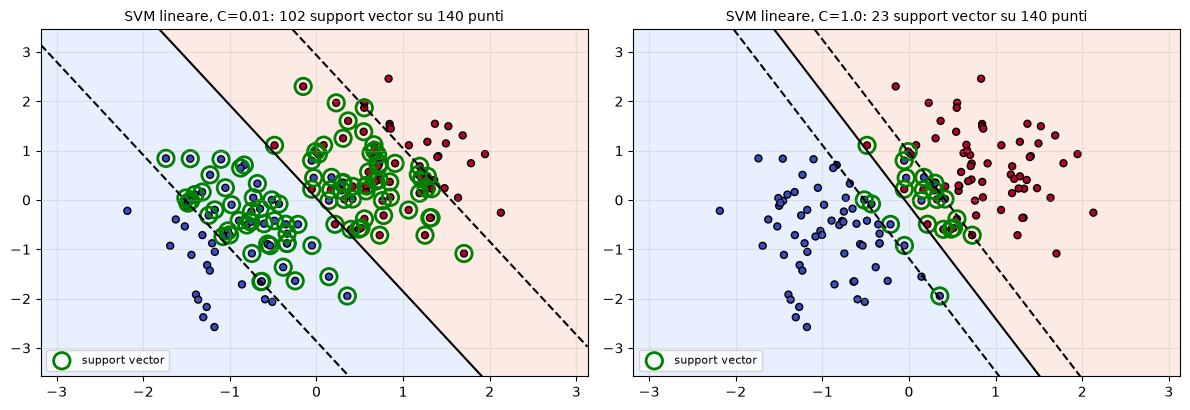

In [8]:
svm_lin = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
Xtr, Xte, ytr, yte = SPLIT["separabile"]
for a, C in zip(ax, [0.01, 1.0]):
    mod = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C)).fit(Xtr, ytr)
    sc, svc = mod[0], mod[1]
    Xs = sc.transform(Xtr)
    xx, yy = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 200),
                         np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 200))
    D = svc.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, D > 0, alpha=.2, cmap=CMAP)
    a.contour(xx, yy, D, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    a.scatter(*Xs.T, c=ytr, cmap=CMAP, edgecolor="k", s=25)
    a.scatter(*svc.support_vectors_.T, s=140, facecolors="none", edgecolors="g", linewidths=2, label="support vector")
    a.set_title(f"SVM lineare, C={C}: {len(svc.support_vectors_)} support vector su {len(Xs)} punti", fontsize=10)
    a.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Cosa guardare.** Le linee tratteggiate sono i bordi del margine, la linea piena il confine. Con **C piccolo** il margine è largo e i support vector sono molti (tollera errori dentro il margine). Con **C grande** il margine si stringe e i support vector diventano pochi.

## A5. SVM con kernel (RBF) `[corso]`

- **Idea**: stessa SVM, ma al posto del prodotto scalare usa una funzione **kernel**. Il kernel RBF misura la somiglianza $\exp(-\gamma\|\mathbf{x}-\mathbf{z}\|^2)$ e permette confini **curvi** senza costruire a mano le feature (*kernel trick*).
- **Peculiarità**: ogni support vector fa da "centro": il modello **si adatta ai dati**, non ha centri fissi scelti a mano `[corso]` (nb 08: *"Gaussian Kernel is not the same as Gaussian features"*).
- **Forte**: confini molto flessibili con poche manopole. Funziona bene su dataset medi.
- **Debole**: lento con molti campioni, **non scala bene**. Molto sensibile a `gamma` e `C`: se esageri va in **overfitting**. Poco interpretabile.
- **Manopole**: `gamma` (raggio d'influenza di ogni punto: grande = confine frastagliato), `C`.

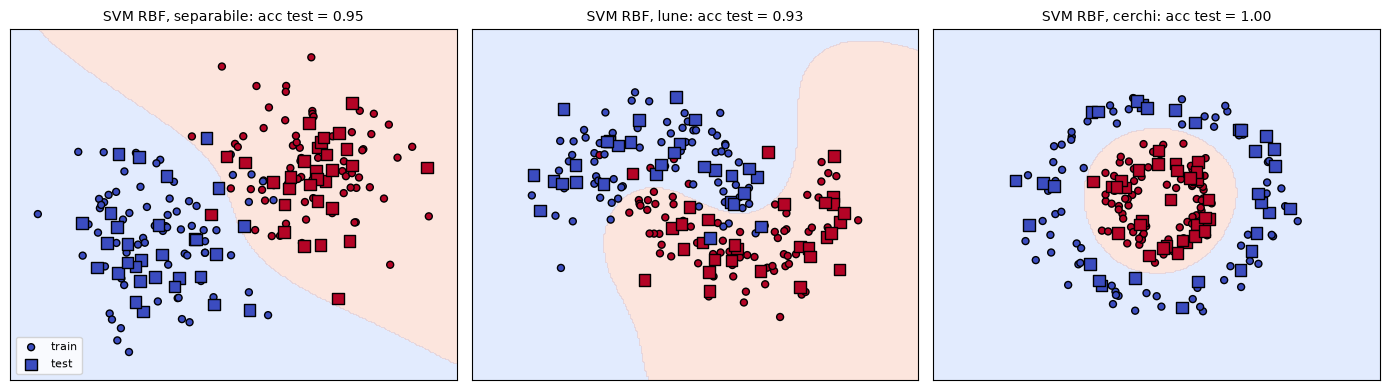

In [9]:
scheda_grafica(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")), "SVM RBF,")

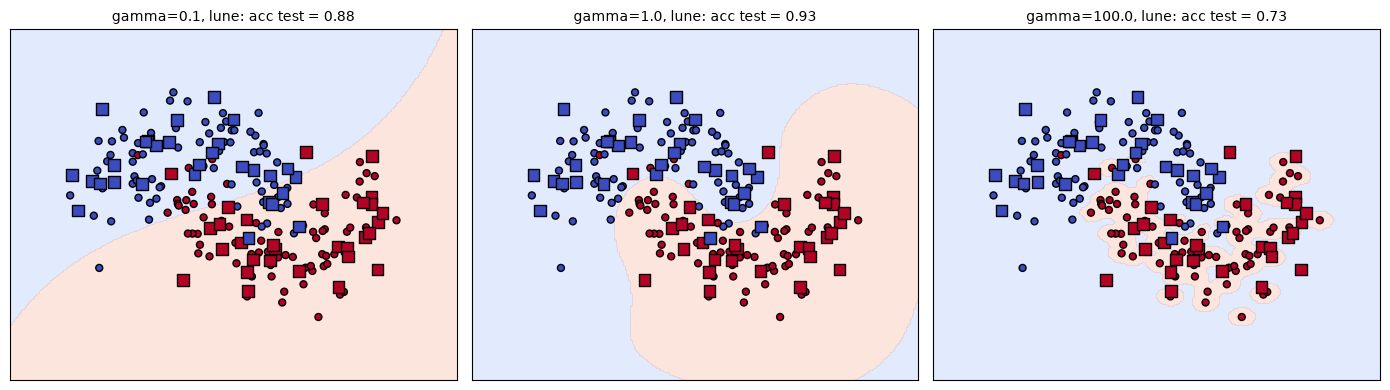

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, g in zip(axs, [0.1, 1.0, 100.0]):
    disegna(ax, make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma=g)), "lune", f"gamma={g},")
plt.tight_layout(); plt.show()

**Cosa guardare.** `gamma` piccolo = confine quasi retto (underfitting), `gamma` giusto = confine ragionevole, `gamma=100` = isole attorno ai singoli punti (overfitting). Controlla anche l'accuracy di test: scende quando il confine "impara a memoria".

## A6. k-NN `[corso]`

- **Idea**: per classificare un punto guarda i **K punti di training più vicini** e vota.
- **Peculiarità**: **non c'è training** e **non ha pesi**: il modello *è* il dataset. Modello **non parametrico**: la complessità cresce con i dati `[corso]`.
- **Forte**: semplicissimo, estensione immediata a più classi, confini di forma qualunque, funziona con **qualunque distanza** (anche custom, vedi esercizio DNA) `[corso]`.
- **Debole**: deve tenere in memoria **tutto** il training e **ogni predizione è lenta** `[corso]`. Sensibile alla scala delle feature e a quelle inutili. Con molte dimensioni le distanze perdono significato `[mio]`.
- **Manopole**: `n_neighbors` = K, che fa da **regolarizzazione**: più K, più confine liscio `[corso]`. Anche la metrica.

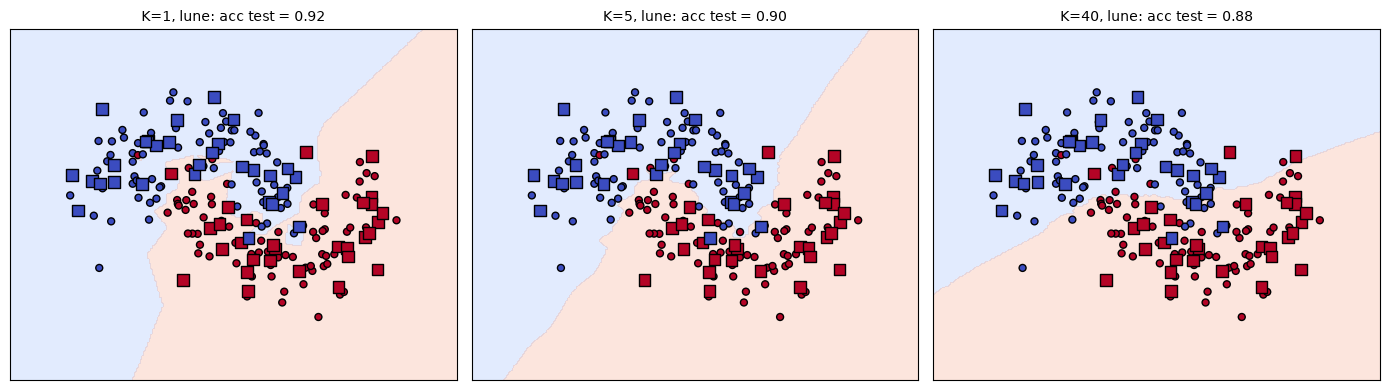

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axs, [1, 5, 40]):
    disegna(ax, make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), "lune", f"K={k},")
plt.tight_layout(); plt.show()

**Cosa guardare.** `K=1` impara a memoria ogni singolo punto (confine frastagliato, overfitting). `K=40` è troppo liscio (underfitting). Questa è la stessa idea di `gamma` nella SVM o di `C` nella logistica: **una manopola che dosa la complessità**.

## A7. LDA come classificatore `[mio]` + `[corso]` per la parte di riduzione

- **Idea**: assume che ogni classe sia una nuvola gaussiana con la **stessa covarianza**; il confine che ne deriva è una retta/iperpiano `[mio]`.
- **Peculiarità**: è sia un classificatore sia (soprattutto nel corso) un metodo di **riduzione di dimensioni supervisionato**: cerca la direzione che massimizza il **Fisher score**, cioè separa le medie delle classi e rimpicciolisce la varianza dentro ogni classe `[corso]` (nb 09).
- **Forte**: veloce, nessuna manopola da tarare, riduce a **al massimo C−1 dimensioni** `[corso]`.
- **Debole**: confine lineare; l'ipotesi gaussiana a covarianza comune può non valere `[mio]`.
- **Manopole**: `n_components` (come riduzione), `solver`.

Il suo uso nel progetto è la parte B (riduzione). Qui lo vediamo come classificatore per confronto.

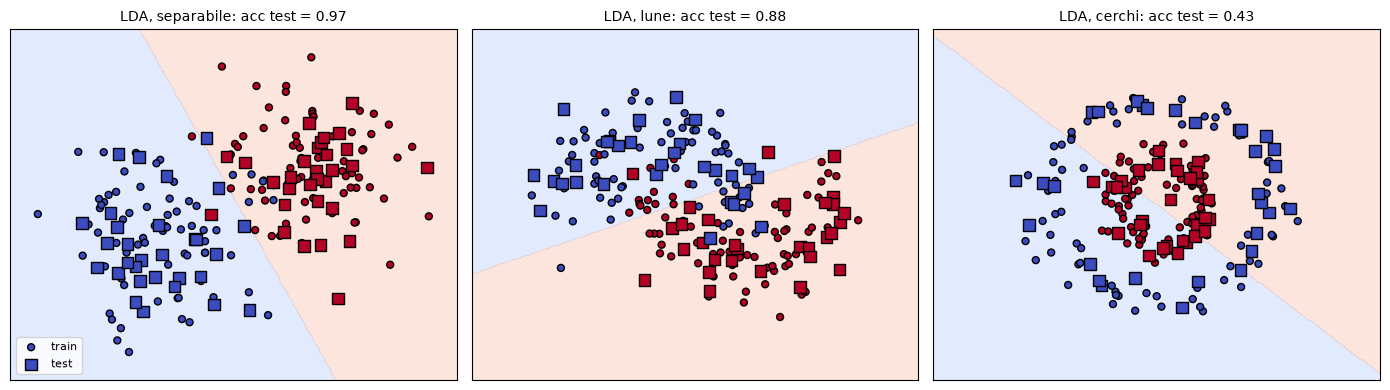

In [12]:
scheda_grafica(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()), "LDA,")

## A8. Confronto: tutti i modelli sugli stessi dati

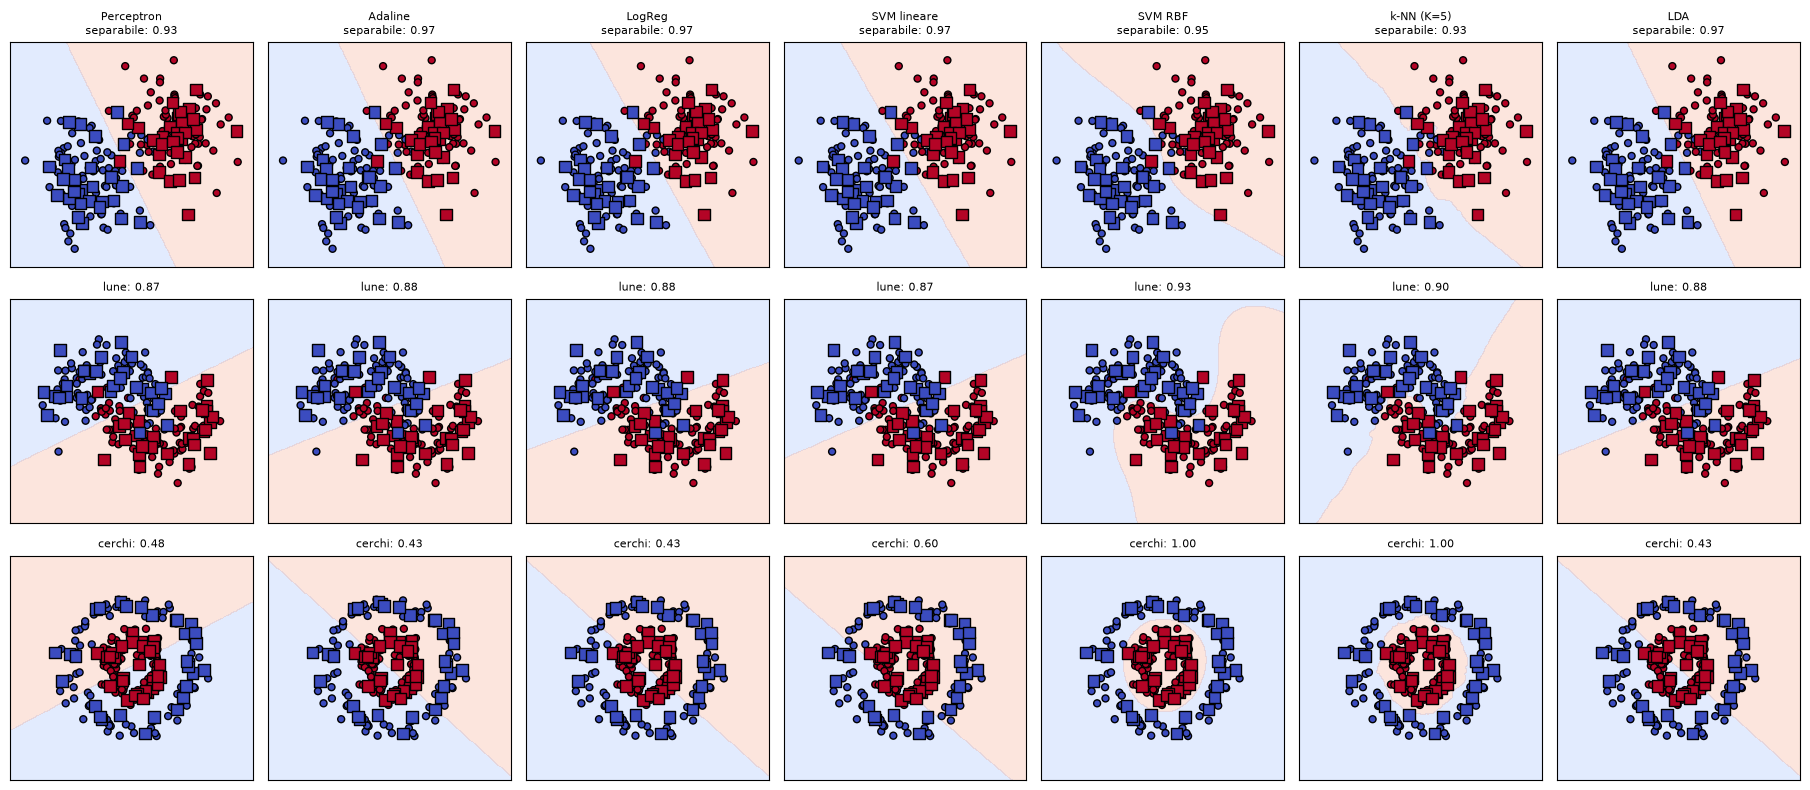

,separabile,lune,cerchi
Perceptron,0.93,0.87,0.48
Adaline,0.97,0.88,0.43
LogReg,0.97,0.88,0.43
SVM lineare,0.97,0.87,0.60
SVM RBF,0.95,0.93,1.00
k-NN (K=5),0.93,0.90,1.00
LDA,0.97,0.88,0.43


In [13]:
MODELLI = {
    "Perceptron": make_pipeline(StandardScaler(), Perceptron(random_state=0)),
    "Adaline": make_pipeline(StandardScaler(), AdalineCF()),
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression()),
    "SVM lineare": make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "SVM RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "k-NN (K=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
}
fig, axs = plt.subplots(3, len(MODELLI), figsize=(2.6 * len(MODELLI), 8))
tab = {}
for j, (nm, mod) in enumerate(MODELLI.items()):
    for i, nome in enumerate(DATI):
        _, acc = disegna(axs[i, j], mod, nome, "")
        axs[i, j].set_title(f"{nm}\n{nome}: {acc:.2f}" if i == 0 else f"{nome}: {acc:.2f}", fontsize=8)
        tab.setdefault(nm, {})[nome] = acc
plt.tight_layout(); plt.show()
pd.DataFrame(tab).T.round(2)

**Attenzione a come leggere la tabella.** È **un solo split** di 60 punti di test: differenze di 0.02-0.03 **non sono significative**. Per decidere sul serio servono la cross-validation e la nested CV (nb 06, slide *Nested cross-validation*). Quello che deve restare in testa è la **forma dei confini**:

| Famiglia | Confine |
|---|---|
| Perceptron, Adaline, LogReg, SVM lineare, LDA | **retta** (ai cerchi non possono arrivare) |
| SVM RBF, k-NN | **curva** qualunque (rischio overfitting) |

### Le tue parole (1)
In una cella di testo qui sotto, spiega a un compagno di corso **perché Perceptron, Adaline e logistica hanno lo stesso confine "a retta" ma sono modelli diversi**.

*(scrivi qui la tua risposta)*

# Parte B. Riduzione delle dimensioni `[corso]` (nb 09)

Serve a due cose: **ridurre il rumore/costo** (meno colonne) e **visualizzare**. Nel template è lo step `dim_reduction`.

Distinzione chiave `[corso]`:
- **Feature selection**: scegli un sottoinsieme delle colonne esistenti (filter, wrapper).
- **Feature extraction**: crei **nuove** colonne combinando quelle vecchie (PCA, LDA, kernel PCA).

Dataset: le cifre scritte a mano di sklearn (64 pixel per immagine, 10 classi). Nota `[mio]`: nel notebook 09 il prof usa un altro dataset di cifre; questo è un dataset giocattolo per avere un grafico subito.

## B1. PCA `[corso]`
- **Idea**: trova le direzioni lungo cui i dati **variano di più** e li proietta lì.
- **Peculiarità**: **lineare** e **non supervisionata**: non guarda le etichette `[corso]`.
- **Forte**: veloce; `n_components` si può scegliere come "quanta varianza voglio tenere" (es. 0.95).
- **Debole**: la direzione di massima varianza **non è detto che separi le classi**. Solo trasformazioni lineari.
- **Manopole**: `n_components` (intero o frazione di varianza spiegata).

## B2. LDA come riduzione `[corso]`
- **Peculiarità**: **supervisionata**. Cerca le direzioni che separano le classi, non quelle di massima varianza.
- **Forte**: con poche componenti separa bene le classi.
- **Debole**: al massimo $C-1$ componenti. Lineare.

## B3. Kernel PCA `[corso]`
- **Peculiarità**: PCA **non lineare** (usa un kernel, come l'SVM). Utile quando la struttura è curva.
- **Debole**: è difficile misurare la varianza spiegata `[corso]`. Costa di più, ha manopole di kernel (`gamma`).

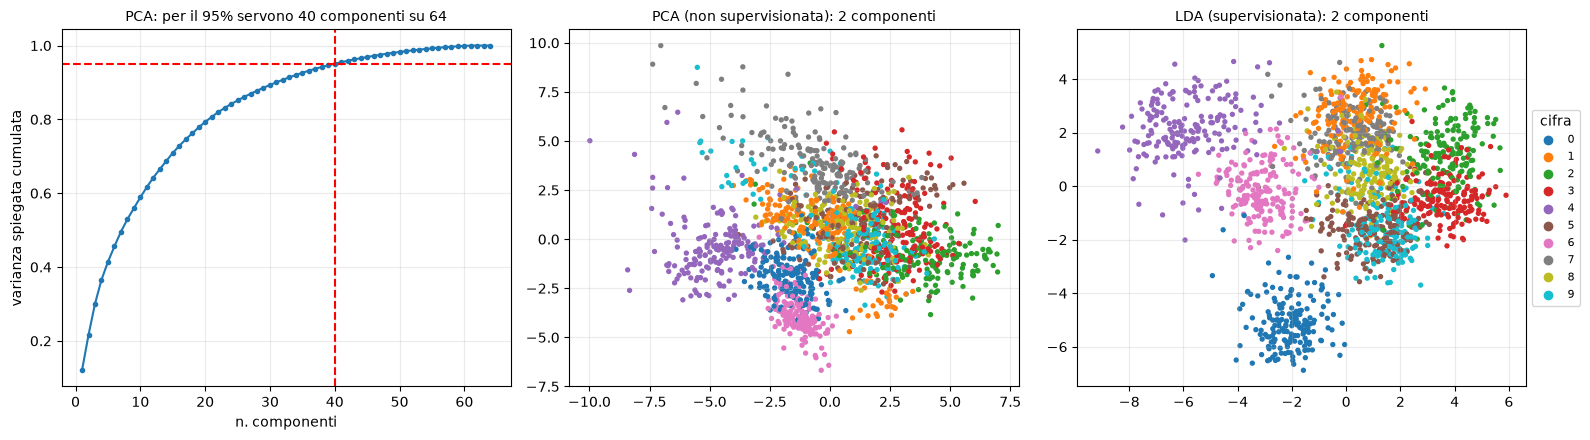

In [14]:
dg = load_digits()
Xd, yd = dg.data, dg.target
Xd = StandardScaler().fit_transform(Xd)

p = PCA().fit(Xd)
cum = np.cumsum(p.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)

pca2 = PCA(n_components=2).fit_transform(Xd)
lda2 = LinearDiscriminantAnalysis(n_components=2).fit(Xd, yd).transform(Xd)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
axs[0].plot(range(1, 65), cum, "o-", ms=3); axs[0].axhline(.95, color="r", ls="--"); axs[0].axvline(k95, color="r", ls="--")
axs[0].set_xlabel("n. componenti"); axs[0].set_ylabel("varianza spiegata cumulata")
axs[0].set_title(f"PCA: per il 95% servono {k95} componenti su 64", fontsize=10)
for a, Z, t in [(axs[1], pca2, "PCA (non supervisionata): 2 componenti"), (axs[2], lda2, "LDA (supervisionata): 2 componenti")]:
    sc = a.scatter(*Z.T, c=yd, cmap="tab10", s=8); a.set_title(t, fontsize=10)
axs[2].legend(*sc.legend_elements(), loc="center left", bbox_to_anchor=(1, .5), title="cifra", fontsize=8)
plt.tight_layout(); plt.show()

**Cosa guardare.** Con le stesse 2 componenti la LDA tiene alcune cifre **più separate** (ad esempio 0, 4 e 6 formano gruppi netti), perché ha visto le etichette. La PCA, che non le ha viste, le mescola di più. Con 2 sole componenti nessuna delle due separa tutte le 10 cifre.

Attenzione però: in questo grafico LDA è stata allenata su **tutti** i dati, solo per disegnare. Nei veri esperimenti la riduzione va **dentro la pipeline**, allenata solo sul training (altrimenti c'è **data leakage**, domanda ancora aperta del template sull'imputazione).

In [15]:
Xtr, Xte, ytr, yte = train_test_split(dg.data, dg.target, test_size=.3, stratify=dg.target, random_state=0)
cand = {
    "dummy": DummyClassifier(strategy="most_frequent"),
    "LogReg su 64 pixel": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    f"PCA(95%) + LogReg": make_pipeline(StandardScaler(), PCA(n_components=.95), LogisticRegression(max_iter=2000)),
    "LDA(9) + LogReg": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=9), LogisticRegression(max_iter=2000)),
}
righe = []
for nm, mod in cand.items():
    cv = cross_val_score(mod, Xtr, ytr, cv=5).mean()
    righe.append((nm, round(cv, 3), round(mod.fit(Xtr, ytr).score(Xte, yte), 3)))
pd.DataFrame(righe, columns=["pipeline", "acc CV (train)", "acc test"]).set_index("pipeline")

,acc CV (train),acc test
pipeline,,
dummy,0.101,0.102
LogReg su 64 pixel,0.964,0.972
PCA(95%) + LogReg,0.957,0.967
LDA(9) + LogReg,0.948,0.950


**Cosa guardare.** Il dummy fa circa 0.1 (10 classi). Le tre pipeline reali stanno tutte molto sopra. Ridurre le dimensioni non è per forza "più accurato": spesso serve per **ridurre la complessità** mantenendo la performance. È una scelta da fare con la CV, non a occhio.

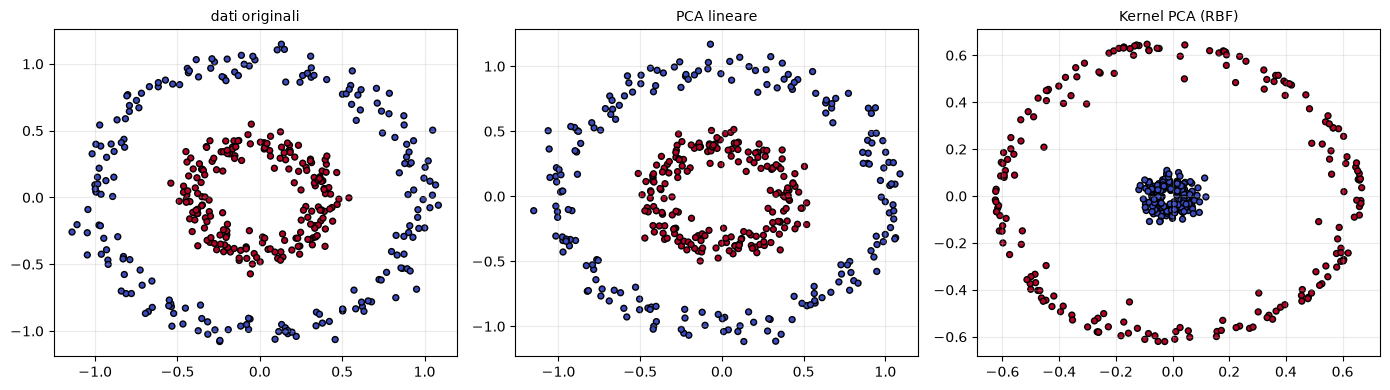

In [16]:
Xc, yc = make_circles(400, noise=0.07, factor=0.4, random_state=0)
Zl = PCA(n_components=2).fit_transform(Xc)
Zk = KernelPCA(n_components=2, kernel="rbf", gamma=8).fit_transform(Xc)
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for a, Z, t in [(axs[0], Xc, "dati originali"), (axs[1], Zl, "PCA lineare"), (axs[2], Zk, "Kernel PCA (RBF)")]:
    a.scatter(*Z.T, c=yc, cmap=CMAP, edgecolor="k", s=18); a.set_title(t, fontsize=10)
plt.tight_layout(); plt.show()

**Cosa guardare.** La PCA lineare è solo una **rotazione**: i cerchi restano uno dentro l'altro. La Kernel PCA li "apre" in modo che le due classi diventino separabili con una **retta** nel nuovo spazio. È lo stesso trucco del kernel nella SVM, applicato alla PCA.

### Le tue parole (2)
Spiega a un compagno **perché la PCA può *non* aiutare un classificatore** mentre la LDA di solito aiuta (pensa a "varianza" contro "separazione tra classi").

*(scrivi qui la tua risposta)*

# Parte C. Regressione `[corso]` (nb 05 e slide)

Qui la risposta è un **numero**, non una classe. La domanda di fondo non cambia: *quanto complesso deve essere il modello?*

## C1. Regressione lineare (OLS)
- **Idea**: la retta $\hat t = \mathbf{w}^\top\mathbf{x}$ che minimizza la somma degli errori al quadrato (RSS).
- **Peculiarità**: ha una **soluzione chiusa** (pseudo-inversa) oppure si usa gradient descent. È lo stesso Adaline, ma su valori continui.
- **Forte**: semplice, interpretabile.
- **Debole**: se la relazione è curva fa **underfitting**; con feature collineari o più feature che campioni la matrice non è invertibile (**rank deficiency**).

## C2. Ridge (regolarizzazione L2) `[corso]`
- **Peculiarità**: aggiunge $\lambda\|\mathbf{w}\|^2$ alla loss: penalizza pesi grandi. $\lambda I+\Phi^\top\Phi$ è **sempre invertibile**.
- **Forte**: argina l'overfitting, risolve la rank deficiency.
- **Manopole**: `alpha` ($\lambda$): grande = pesi piccoli, modello più semplice.

## C3. Polinomi: non è un modello, è un trucco
`PolynomialFeatures` aggiunge $x^2, x^3,\dots$ come **nuove colonne**; il modello resta una regressione **lineare nei pesi**. Il grado è un iperparametro di complessità.

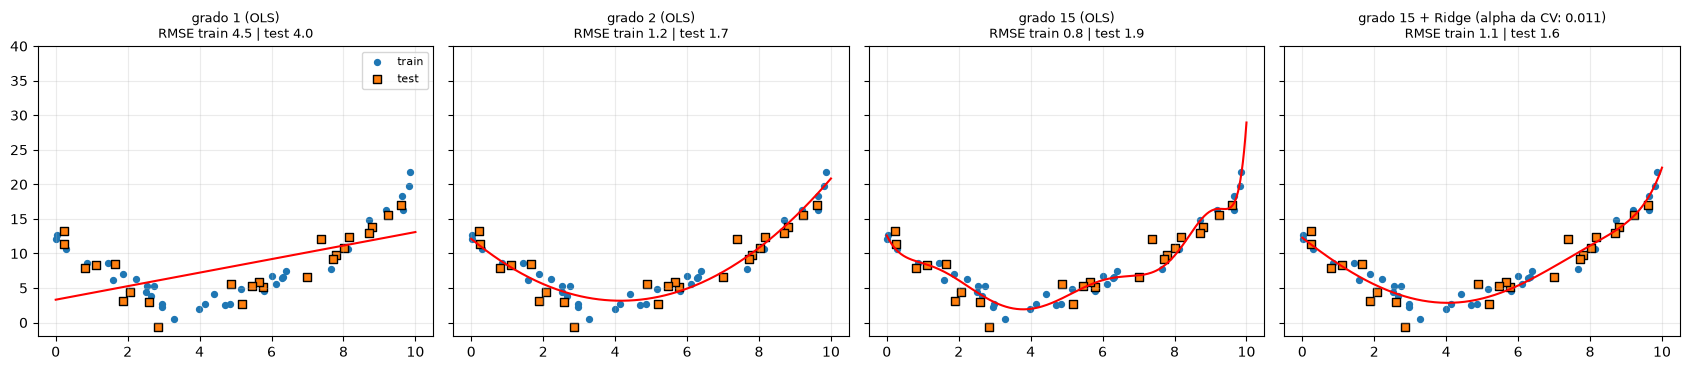

In [17]:
rng = np.random.RandomState(5)
x = rng.uniform(0, 10, 60)
t = 3 + 0.5 * (x - 4) ** 2 + rng.normal(0, 1.5, 60)
Xr = x.reshape(-1, 1)
Xrtr, Xrte, trtr, trte = train_test_split(Xr, t, test_size=.4, random_state=0)
xg = np.linspace(0, 10, 300).reshape(-1, 1)

mods = {
    "grado 1 (OLS)": make_pipeline(StandardScaler(), LinearRegression()),
    "grado 2 (OLS)": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "grado 15 (OLS)": make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), LinearRegression()),
    "grado 15 + Ridge": make_pipeline(PolynomialFeatures(15, include_bias=False), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 2, 20), cv=5)),
}
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
for a, (nm, mod) in zip(axs, mods.items()):
    mod.fit(Xrtr, trtr)
    a.scatter(Xrtr, trtr, s=18, label="train"); a.scatter(Xrte, trte, s=40, marker="s", edgecolor="k", label="test")
    a.plot(xg, mod.predict(xg), "r"); a.set_ylim(-2, 40)
    extra = f" (alpha da CV: {mod[-1].alpha_:.2g})" if "Ridge" in nm else ""
    a.set_title(f"{nm}{extra}\nRMSE train {rmse(trtr, mod.predict(Xrtr)):.1f} | test {rmse(trte, mod.predict(Xrte)):.1f}", fontsize=9)
axs[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Cosa guardare.** Grado 1: errore alto su train **e** test (underfitting, *bias alto*). Grado 2: giusto, perché i dati vengono da una parabola. Grado 15: l'errore di train scende ancora, ma il test **non migliora** rispetto al grado 2, e la curva oscilla e "esplode" vicino a x=10 (overfitting, *varianza alta*). Grado 15 con Ridge: `alpha` è scelto con la cross-validation **sul solo training** e la curva torna liscia; guarda i numeri nel titolo per vedere cosa succede a train e test.

Nota: il test ha pochi punti (24), quindi guarda la **forma** delle curve più dei decimali. E ricordati: `alpha` va scelto con la CV, **mai guardando il test**.

# Parte D. Le "manopole" e come si scelgono `[corso]` (nb 06 e slide)

Ogni modello ha una manopola di complessità. Il filo che li unisce:

| Modello | Manopola | Troppo "basso" | Troppo "alto" |
|---|---|---|---|
| Logistica | `C` | troppa regolarizzazione (underfit) | poca (overfit) |
| SVM RBF | `gamma`, `C` | confine troppo retto | isole attorno ai punti |
| k-NN | `K` | `K` grande: troppo liscio | `K=1`: impara a memoria |
| Polinomio | grado | retta su dati curvi | oscilla tra i punti |
| Ridge | `alpha` | pesi liberi (overfit) | pesi quasi zero (underfit) |

Si sceglie con **validation curve** (una manopola) o **GridSearchCV / RandomizedSearchCV** (più manopole insieme), dentro la CV. Per stimare onestamente la performance del tutto si usa la **nested CV**.

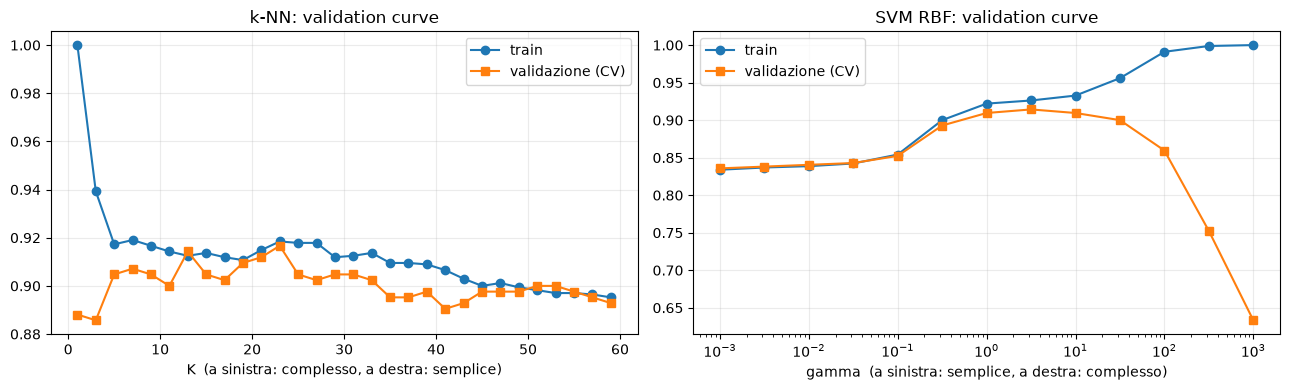

K migliore per k-NN: 23 | gamma migliore per SVM: 3.1622776601683795


In [18]:
Xm, ym = make_moons(600, noise=0.3, random_state=1)
Xmtr, Xmte, ymtr, ymte = train_test_split(Xm, ym, test_size=.3, stratify=ym, random_state=0)

ks = np.arange(1, 60, 2)
tr, va = validation_curve(make_pipeline(StandardScaler(), KNeighborsClassifier()), Xmtr, ymtr,
                          param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=5)
gs = np.logspace(-3, 3, 13)
tr2, va2 = validation_curve(make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)), Xmtr, ymtr,
                            param_name="svc__gamma", param_range=gs, cv=5)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(ks, tr.mean(1), "o-", label="train"); axs[0].plot(ks, va.mean(1), "s-", label="validazione (CV)")
axs[0].set_xlabel("K  (a sinistra: complesso, a destra: semplice)"); axs[0].set_title("k-NN: validation curve"); axs[0].legend()
axs[1].semilogx(gs, tr2.mean(1), "o-", label="train"); axs[1].semilogx(gs, va2.mean(1), "s-", label="validazione (CV)")
axs[1].set_xlabel("gamma  (a sinistra: semplice, a destra: complesso)"); axs[1].set_title("SVM RBF: validation curve"); axs[1].legend()
plt.tight_layout(); plt.show()
print("K migliore per k-NN:", int(ks[va.mean(1).argmax()]), "| gamma migliore per SVM:", float(gs[va2.mean(1).argmax()]))

**Cosa guardare.** In entrambi i grafici la curva di **train** sale con la complessità (a sinistra per K, a destra per gamma). Nella **SVM** la curva di validazione sale e poi **crolla**: il punto in cui si stacca dal train è l'overfitting. Nel **k-NN** l'effetto è molto più piccolo e rumoroso (differenze di 1-3 punti percentuali): con `K=1` il train è 1.00 ma la validazione è tra le più basse. Scegli la manopola dove la validazione è massima, **non** dove il train è massimo.

### Le tue parole (3)
Con un esempio a scelta (k-NN o SVM), spiega a un compagno **cosa vuol dire** che la validation curve "scende" mentre il train sale, e cosa faresti nel progetto.

*(scrivi qui la tua risposta)*

# Mappa mentale finale

| Modello | Tipo | Peculiarità (in una riga) | Forte | Debole | Manopola principale |
|---|---|---|---|---|---|
| Dummy | baseline | ignora le feature | metro minimo | non è un candidato | strategy |
| Perceptron | lineare | errore di soglia (0/1) | converge se separabile | non si stabilizza altrimenti | eta0, max_iter |
| Adaline | lineare | errore quadratico su $z$ | minimo ben definito | punisce i punti "troppo giusti" | $\eta$, epoche |
| Logistica | lineare | sigmoide e log-loss: probabilità | interpretabile, soglia regolabile | confine lineare | C |
| SVM lineare | lineare | margine massimo, support vector | scelta unica tra infinite rette | niente probabilità dirette | C |
| SVM RBF | non lineare | kernel: confine curvo | flessibile, centri adattivi | lenta, sensibile | gamma, C |
| k-NN | non parametrico | niente training, vota i vicini | semplice, qualunque distanza | memoria e predizione lente | K |
| PCA | riduzione | direzioni di massima varianza (non supervisionata) | veloce, scelta per varianza | può non separare le classi | n_components |
| LDA | riduzione/class. | direzioni di massima separazione (supervisionata) | poche componenti utili | al più C−1 componenti | n_components |
| Kernel PCA | riduzione | PCA non lineare con kernel | struttura curva | varianza difficile da misurare | kernel, gamma |
| Ridge | regressione | OLS + penalità L2 | contiene overfitting, sempre invertibile | un'altra manopola | alpha |

**Tre domande per orientarti quando scegli un modello** `[mio]`:
1. Il confine deve essere **retta o curva**? (lineare vs kernel/k-NN)
2. Mi servono le **probabilità** o posso accontentarmi di una classe? (logistica vs SVM)
3. Quanti **campioni** e **dimensioni** ho? (k-NN e SVM RBF soffrono con tanti campioni; PCA/LDA aiutano con tante dimensioni)

# Cosa manca ancora (programma del corso, non ancora nel repo)

Dal programma `[corso]`: **Decision Tree**, **ensemble** (bagging, Random Forest, boosting/XGBoost), **clustering** (k-means, gerarchico, density-based). Quando li studieremo aggiungeremo qui una scheda per ciascuno con le stesse cinque voci. La **Random Forest** serve anche per il template del progetto.

# Spazio libero per i tuoi appunti

*(scrivi qui)*